# Research design and cost–error tradeoffs

What evidence would make a surrogate useful for a stated scientific question?

Fall 2024.


# Cost is conditional on a workflow
Before running, list what you would include in setup and in one query. Predict whether a known analytic solution is a necessary baseline for this toy problem.

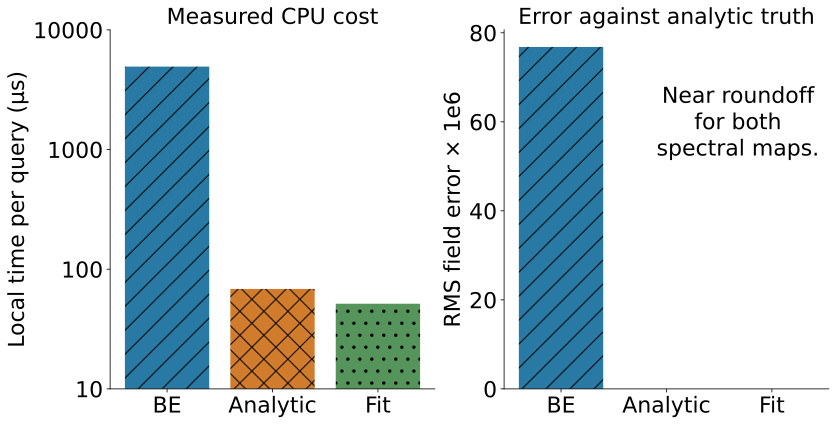

BE reference 0.004928990453481674 seconds/query {'rms': 7.681545556807753e-05, 'relative_l2': 7.521919794216353e-05, 'max_error': 0.00015267190908274664, 'mean_error': 4.3989118921038676e-14}
Analytic spectral 6.838170811533928e-05 seconds/query {'rms': 1.0055412576335686e-16, 'relative_l2': 9.846456853975071e-17, 'max_error': 2.220446049250313e-16, 'mean_error': 2.6020852139652106e-18}
3-mode fit 5.143657326698303e-05 seconds/query {'rms': 1.4288057044435644e-16, 'relative_l2': 1.3991145181477784e-16, 'max_error': 2.220446049250313e-16, 'mean_error': 8.673617379884035e-18}


In [1]:
import numpy as np
from demo import run,learned_decay
from IPython.display import SVG,display
results=run()
display(SVG(filename="cost-error.svg"))
for row in results["query_methods"]:
    print(row["method"],row["median_seconds_per_query"],"seconds/query",row["error"])

## Implement cost accounting
Complete the saving per query. Return no threshold when the surrogate is not cheaper per query. This guided example uses the notes, not the assigned numbers.

In [2]:
def my_break_even(setup,reference,surrogate):
    saving=None  # TODO: reference cost minus surrogate cost
    if saving is None:
        return None
    return np.inf if saving<=0 else setup/saving
trial=my_break_even(12,0.20,0.02)
if trial is None:
    print("Complete the saving expression, then rerun.")
else:
    np.testing.assert_allclose(trial,66.66666666666667)
    print("Strict break-even requires an integer above",trial)

Complete the saving expression, then rerun.


## Predict the inference-step result
The fitted rate is selected to match an Euler update at0.1. Predict whether halving only the inference step must improve agreement with the true decay.

step 0.1 learned rate -1.8126924692201813 value 0.3678794411714422 error 1.1102230246251565e-16
step 0.05 learned rate -1.8126924692201813 value 0.3867088820539591 error 0.018829440882516757
step 0.025 learned rate -1.8126924692201813 value 0.395531382456595 error 0.027651941285152692
step 0.0125 learned rate -1.8126924692201813 value 0.39980740974445933 error 0.031927968573016996


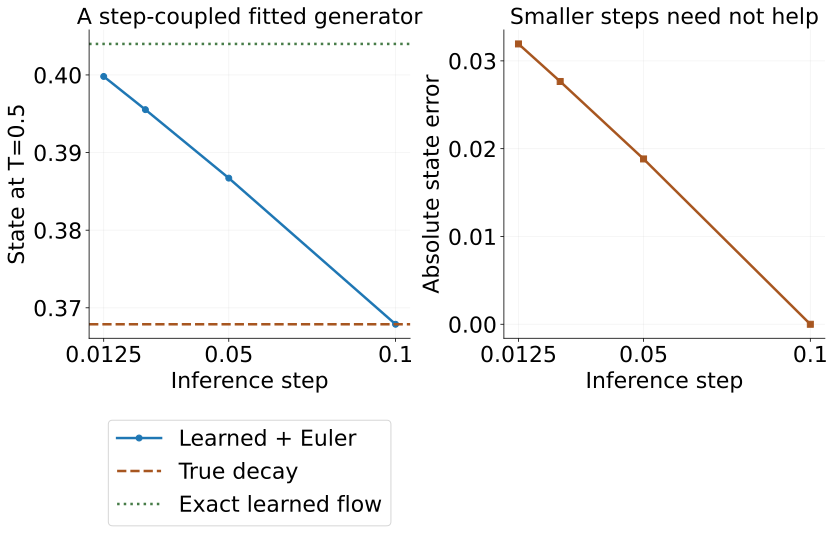

In [3]:
for step in [0.1,0.05,0.025,0.0125]:
    value,generator=learned_decay(step)
    print("step",step,"learned rate",generator,"value",value,"error",abs(value-np.exp(-1)))
display(SVG(filename="learned-step.svg"))

## Modify training resolution
Refit the scalar generator through a smaller training step0.05, then compare equal and half-sized inference steps. Keep the true rate and horizon fixed. Explain which error source changed.

In [4]:
for step in [0.05,0.025]:
    value,generator=learned_decay(step,training_step=0.05)
    print(step,generator,value,abs(value-np.exp(-1)))

0.05 -1.9032516392808085 0.3678794411714421 2.220446049250313e-16
0.025 -1.9032516392808085 0.3771884271139821 0.00930898594253976


Write a short protocol: claim, held-out unit, reference check, metric, timing boundary, failure criterion and one missing validation measurement. The proposed report is new reconstructed practice, not a recovered historical assignment.